In [1]:
print("In the name of Allah")

In the name of Allah


In [2]:
import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cu128
CUDA available: True
Using device: cuda


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [4]:
print(os.listdir(path))

['Training', 'Testing']


In [5]:
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

print("Training classes:")
print(os.listdir(train_dir))

print("\nTesting classes:")
print(os.listdir(test_dir))

Training classes:
['pituitary', 'notumor', 'meningioma', 'glioma']

Testing classes:
['pituitary', 'notumor', 'meningioma', 'glioma']


In [6]:
for class_name in os.listdir( train_dir ) :
  class_path = os.path.join( train_dir, class_name )
  print( class_name, " : ", len( os.listdir( class_path ) ) )

pituitary  :  1400
notumor  :  1400
meningioma  :  1400
glioma  :  1400


In [7]:
for class_name in os.listdir( test_dir ) :
  class_path = os.path.join( test_dir, class_name )
  print( class_name, " : ", len( os.listdir( class_path ) ) )

pituitary  :  400
notumor  :  400
meningioma  :  400
glioma  :  400


In [8]:
import os, shutil, random

random.seed(42)

src_root = "/kaggle/input/brain-tumor-mri-dataset"

# New writable locations
train_dir = "/content/data/Training"
validation_dir = "/content/data/Validation"
test_dir = os.path.join(src_root, "Testing")

# Start clean so no old copies remain
shutil.rmtree("/content/data", ignore_errors=True)
shutil.rmtree("/content/Validation", ignore_errors=True)

# 1. Copy Training to a writable folder
shutil.copytree(os.path.join(src_root, "Training"), train_dir)

os.makedirs(validation_dir, exist_ok=True)

# 2. Move 400 images per class into Validation
for class_name in sorted(os.listdir(train_dir)):

    class_train_dir = os.path.join(train_dir, class_name)
    class_val_dir = os.path.join(validation_dir, class_name)

    os.makedirs(class_val_dir, exist_ok=True)

    images = sorted(
        f for f in os.listdir(class_train_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    random.shuffle(images)
    selected_images = images[:400]

    for image_name in selected_images:
        shutil.move(
            os.path.join(class_train_dir, image_name),
            os.path.join(class_val_dir, image_name)
        )

print("Validation dataset created.")

Validation dataset created.


In [9]:
for class_name in os.listdir(validation_dir):

    class_path = os.path.join(validation_dir, class_name)

    print(class_name, " : ", len(os.listdir(class_path)))

glioma  :  400
meningioma  :  400
pituitary  :  400
notumor  :  400


## Data Preprocessing & Data Augmentation

In [10]:
IMAGE_SIZE = 128
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [11]:
# Create datasets

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    validation_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Class names:", train_dataset.classes)
print("Class-to-index:", train_dataset.class_to_idx)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class-to-index: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Train: 4000
Validation: 1600
Test: 1600


In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [13]:
class BrainTumorCNN(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x

In [14]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = BrainTumorCNN(num_classes=4).to(device)

print(model)

BrainTumorCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

In [15]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 390404


In [16]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 30

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [17]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [18]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_acc = 0.0


for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # -------------------------
    # Validation
    # -------------------------
    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    # -------------------------
    # Store metrics
    # -------------------------
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # -------------------------
    # Scheduler
    # -------------------------
    scheduler.step(val_loss)

    # Current learning rate
    current_lr = optimizer.param_groups[0]["lr"]

    # -------------------------
    # Print results
    # -------------------------
    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # -------------------------
    # Save best model
    # -------------------------
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "best_brain_tumor_cnn.pth"
        )

        print("Best model saved.")


print(
    "\nBest validation accuracy:",
    f"{best_val_acc * 100:.2f}%"
)

Epoch [01/30] | Train Loss: 0.8214 | Train Acc: 0.6700 | Val Loss: 0.6186 | Val Acc: 0.7625 | LR: 0.001000
Best model saved.
Epoch [02/30] | Train Loss: 0.6674 | Train Acc: 0.7370 | Val Loss: 0.6807 | Val Acc: 0.7106 | LR: 0.001000
Epoch [03/30] | Train Loss: 0.6343 | Train Acc: 0.7480 | Val Loss: 0.6022 | Val Acc: 0.7631 | LR: 0.001000
Best model saved.
Epoch [04/30] | Train Loss: 0.5962 | Train Acc: 0.7718 | Val Loss: 0.5673 | Val Acc: 0.7781 | LR: 0.001000
Best model saved.
Epoch [05/30] | Train Loss: 0.5478 | Train Acc: 0.7877 | Val Loss: 0.7843 | Val Acc: 0.6806 | LR: 0.001000
Epoch [06/30] | Train Loss: 0.5404 | Train Acc: 0.7923 | Val Loss: 0.5154 | Val Acc: 0.7794 | LR: 0.001000
Best model saved.
Epoch [07/30] | Train Loss: 0.5043 | Train Acc: 0.8097 | Val Loss: 0.4294 | Val Acc: 0.8106 | LR: 0.001000
Best model saved.
Epoch [08/30] | Train Loss: 0.4828 | Train Acc: 0.8223 | Val Loss: 0.4072 | Val Acc: 0.8438 | LR: 0.001000
Best model saved.
Epoch [09/30] | Train Loss: 0.4824 |

In [19]:
model.load_state_dict(
    torch.load(
        "best_brain_tumor_cnn.pth",
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


## Training Curves


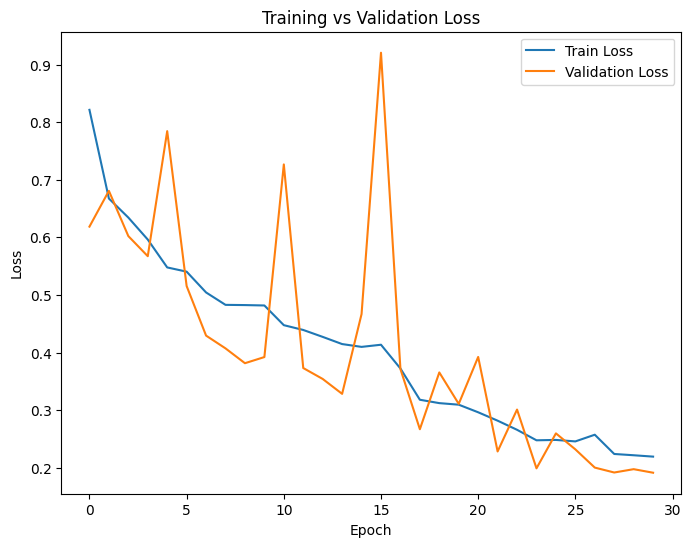

In [20]:
plt.figure(figsize=(8, 6))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

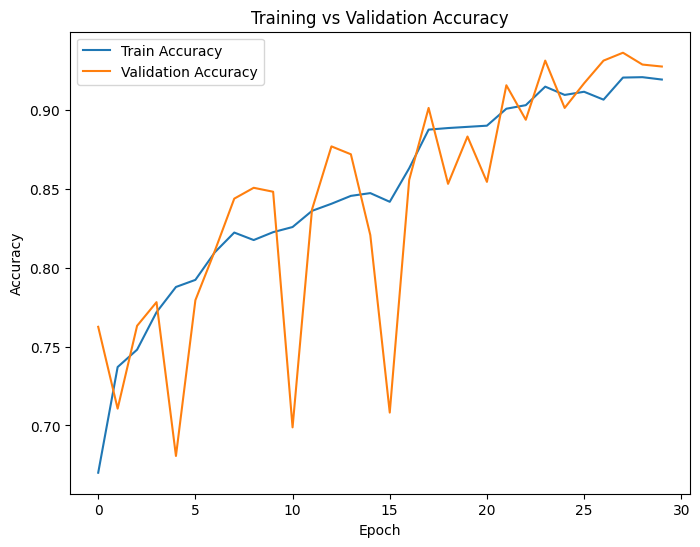

In [21]:
plt.figure(figsize=(8, 6))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

## Model Evaluation

In [22]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)


test_accuracy = (
    all_predictions == all_labels
).mean()


print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.8775
Test Accuracy: 87.75%


In [23]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9816    0.6675    0.7946       400
  meningioma     0.7872    0.8600    0.8220       400
     notumor     0.8618    0.9975    0.9247       400
   pituitary     0.9206    0.9850    0.9517       400

    accuracy                         0.8775      1600
   macro avg     0.8878    0.8775    0.8732      1600
weighted avg     0.8878    0.8775    0.8732      1600



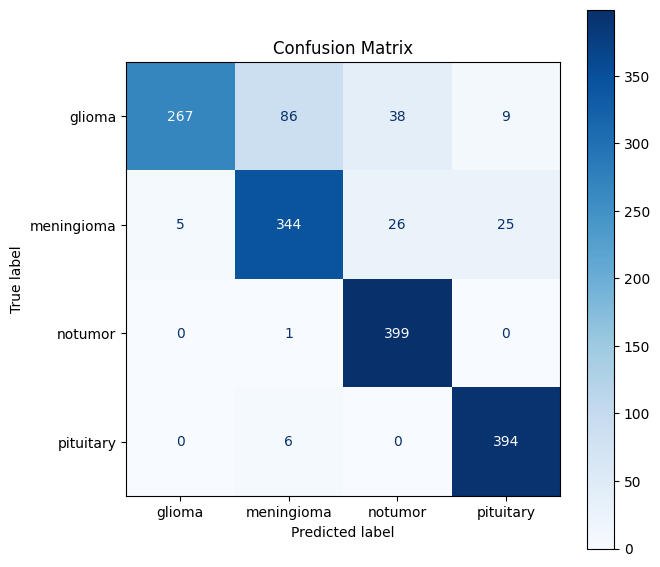

In [24]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

fig, ax = plt.subplots(figsize=(7, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix")
plt.show()

## Prediction & Inference

In [25]:
def predict_image(model, image_path, class_names, device):
    model.eval()

    image = Image.open(image_path).convert("RGB")

    # Same preprocessing used for validation/test
    input_tensor = eval_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)

        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, dim=1)

    predicted_class = class_names[predicted_idx.item()]
    confidence = confidence.item()

    return image, predicted_class, confidence, probabilities.cpu().numpy()[0]

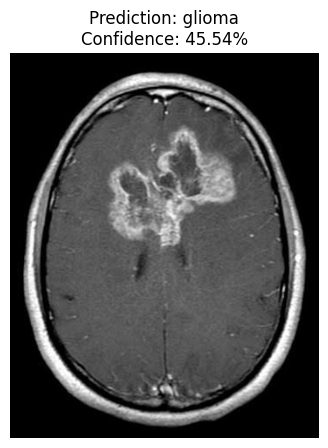

Image: /kaggle/input/brain-tumor-mri-dataset/Testing/glioma/Te-gl_1.jpg
Predicted class: glioma
Confidence: 45.54%

Class probabilities:
glioma      : 45.54%
meningioma  : 38.13%
notumor     : 3.80%
pituitary   : 12.53%


In [26]:
# Pick one test image automatically

sample_path = test_dataset.samples[0][0]

image, predicted_class, confidence, probabilities = predict_image(
    model,
    sample_path,
    test_dataset.classes,
    device
)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)
plt.axis("off")
plt.show()

print("Image:", sample_path)
print("Predicted class:", predicted_class)
print("Confidence:", f"{confidence:.2%}")

print("\nClass probabilities:")
for class_name, prob in zip(test_dataset.classes, probabilities):
    print(f"{class_name:12s}: {prob:.2%}")